# 01 — Exploratory Data Analysis

PJM East (PJME) hourly load joined with Philadelphia hourly temperature
(Open-Meteo). Build the dataset first with `python -m src.build_dataset`.

Questions:
1. Is the data clean (gaps, duplicates)?
2. What is the long-term trend?
3. What do daily, weekly, and seasonal cycles look like?
4. How does temperature relate to load?

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import DATA_QUALITY_JSON, DATASET_PARQUET, FIGURES_DIR, TARGET
from src.plot_style import SERIES, apply_style

apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATASET_PARQUET)
df["hour"] = df.index.hour
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["year"] = df.index.year
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
df["season"] = df["month"].map(SEASONS)
print(f"{len(df):,} hourly rows from {df.index.min()} to {df.index.max()}")

145,392 hourly rows from 2002-01-01 01:00:00 to 2018-08-03 00:00:00


## 1. Data quality
Report produced by `src/build_dataset.py`.

In [2]:
print(json.dumps(json.loads(DATA_QUALITY_JSON.read_text()), indent=2))
df[[TARGET, "temperature_2m"]].describe().round(1)

{
  "raw_rows": 145366,
  "start": "2002-01-01 01:00:00",
  "end": "2018-08-03 00:00:00",
  "missing_values": 0,
  "duplicate_timestamps": 4,
  "missing_timestamps": 30,
  "interpolated_hours": 30,
  "unfilled_hours": 0,
  "weather_missing_after_join": 0,
  "final_rows": 145392
}


,load_mw,temperature_2m
count,145392.0,145392.0
mean,32078.9,12.8
std,6464.3,10.3
min,14544.0,-21.9
25%,27571.0,4.5
50%,31420.0,13.3
75%,35647.0,21.3
max,62009.0,39.8


In [3]:
# Suspicious values: hours far below the typical minimum.
low = df[df[TARGET] < df[TARGET].quantile(0.0001)]
print(f"Hours below the 0.01% quantile ({df[TARGET].quantile(0.0001):,.0f} MW): {len(low)}")
low[[TARGET, "temperature_2m"]].head(10)

Hours below the 0.01% quantile (18,991 MW): 15


,load_mw,temperature_2m
timestamp,,
2012-10-29 23:00:00,17422.0,12.8
2012-10-30 00:00:00,15919.0,11.2
2012-10-30 01:00:00,15390.0,10.0
2012-10-30 02:00:00,14955.0,9.0
2012-10-30 03:00:00,14586.0,8.2
2012-10-30 04:00:00,14544.0,7.8
2012-10-30 05:00:00,14821.0,7.7
2012-10-30 06:00:00,15526.0,7.8
2012-10-30 07:00:00,16688.0,8.0


## 2. Long-term trend

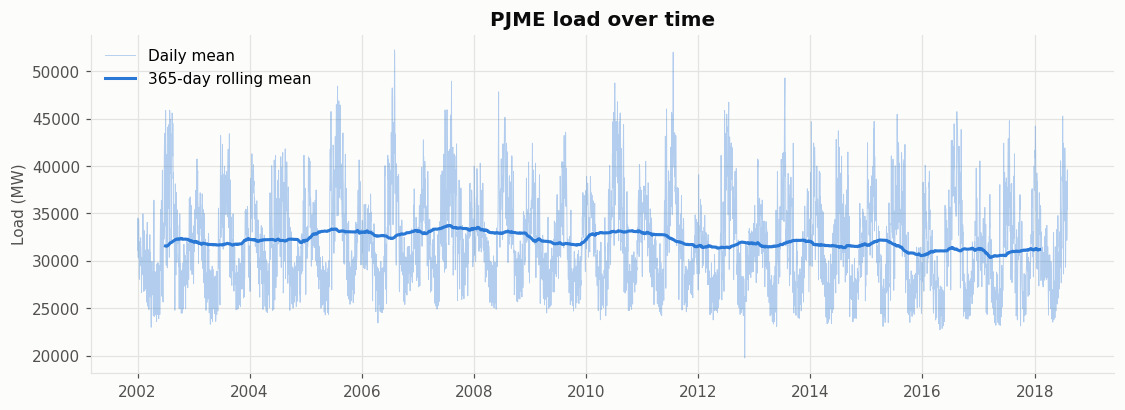

year,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
mean_load_mw,31564.0,31697.0,32268.0,33308.0,32407.0,33611.0,32928.0,31849.0,33099.0,32366.0,31439.0,31705.0,31497.0,31710.0,31338.0,30652.0,31782.0


In [4]:
daily = df[TARGET].resample("D").mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily, color=SERIES[0], linewidth=0.6, alpha=0.35, label="Daily mean")
ax.plot(daily.index, daily.rolling(365, center=True).mean(), color=SERIES[0], label="365-day rolling mean")
ax.set_title("PJME load over time")
ax.set_ylabel("Load (MW)")
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "eda_01_trend.png")
plt.show()

df.groupby("year")[TARGET].mean().round(0).to_frame("mean_load_mw").T

## 3. Hourly profile by season

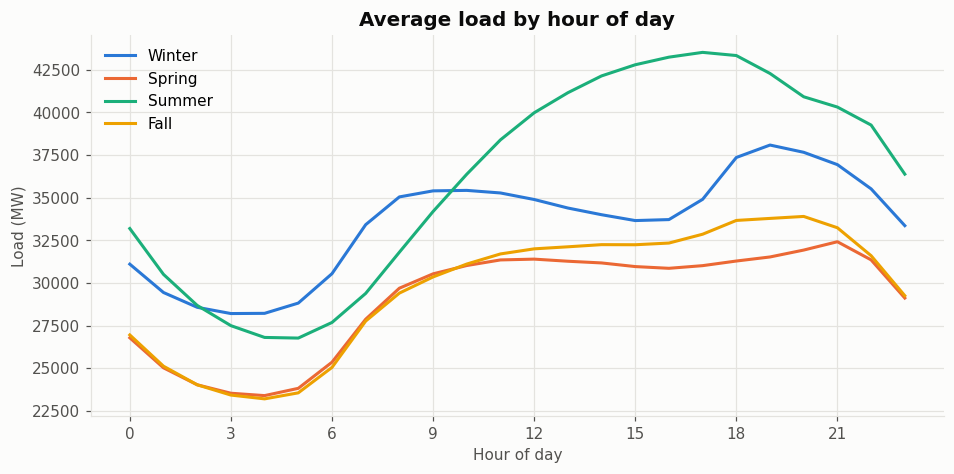

In [5]:
profile = df.groupby(["season", "hour"])[TARGET].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4.5))
for color, season in zip(SERIES, ["Winter", "Spring", "Summer", "Fall"]):
    ax.plot(profile.index, profile[season], color=color, label=season)
ax.set_title("Average load by hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Load (MW)")
ax.set_xticks(range(0, 24, 3))
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "eda_02_hourly_profile.png")
plt.show()

## 4. Day of week

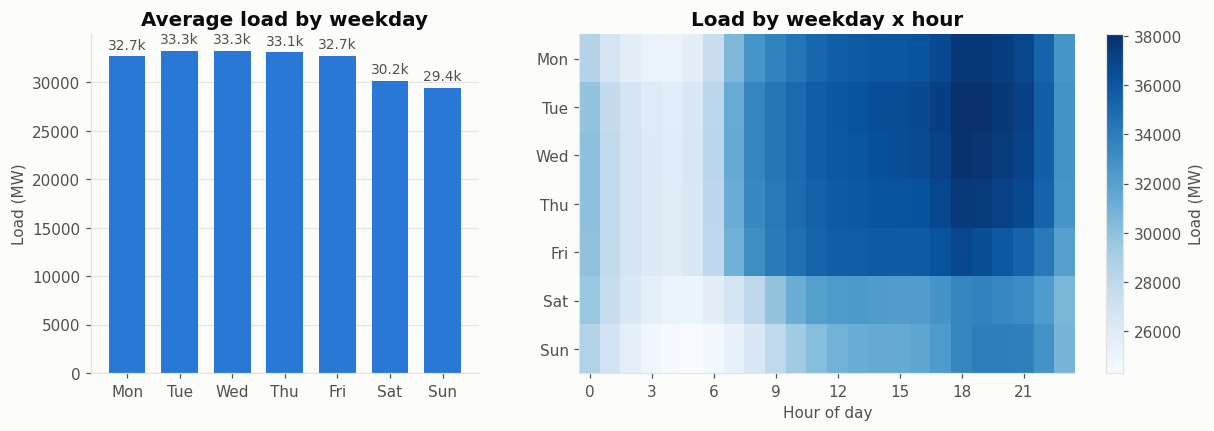

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
mean_load_mw,32672.0,33272.0,33261.0,33086.0,32688.0,30163.0,29406.0


In [6]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = df.groupby(["day_of_week", "hour"])[TARGET].mean().unstack(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.6]})

by_day = df.groupby("day_of_week")[TARGET].mean()
bars = axes[0].bar(DAYS, by_day, color=SERIES[0], width=0.7)
axes[0].bar_label(bars, labels=[f"{v / 1000:.1f}k" for v in by_day], padding=3,
                  fontsize=9, color="#52514e")
axes[0].grid(axis="x", visible=False)
axes[0].set_title("Average load by weekday")
axes[0].set_ylabel("Load (MW)")

im = axes[1].imshow(heat, aspect="auto", cmap="Blues")
axes[1].set_yticks(range(7), DAYS)
axes[1].set_xticks(range(0, 24, 3))
axes[1].set_xlabel("Hour of day")
axes[1].set_title("Load by weekday x hour")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="Load (MW)")
fig.savefig(FIGURES_DIR / "eda_03_day_of_week.png")
plt.show()
by_day.set_axis(DAYS).round(0).to_frame("mean_load_mw").T

## 5. Seasonality by month

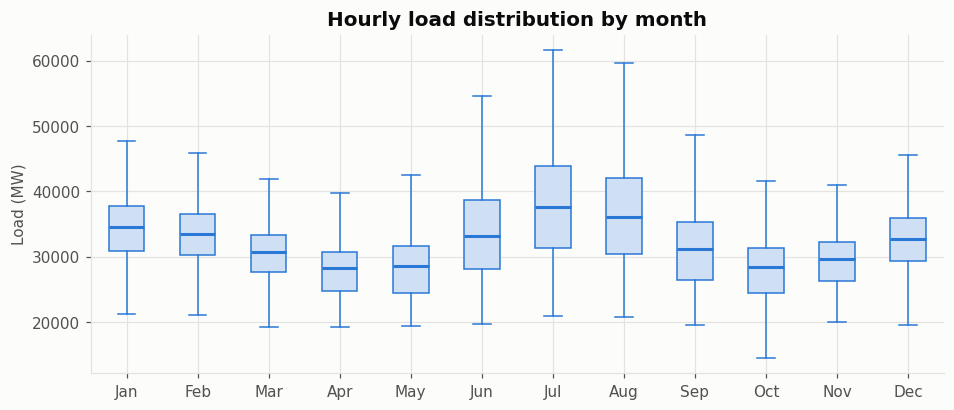

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
months = [df.loc[df["month"] == m, TARGET] for m in range(1, 13)]
ax.boxplot(months, tick_labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug",
                                "Sep", "Oct", "Nov", "Dec"],
           showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#cfe0f5", "edgecolor": SERIES[0]},
           medianprops={"color": SERIES[0], "linewidth": 2},
           whiskerprops={"color": SERIES[0]}, capprops={"color": SERIES[0]})
ax.set_title("Hourly load distribution by month")
ax.set_ylabel("Load (MW)")
fig.savefig(FIGURES_DIR / "eda_04_monthly.png")
plt.show()

## 6. Temperature vs load

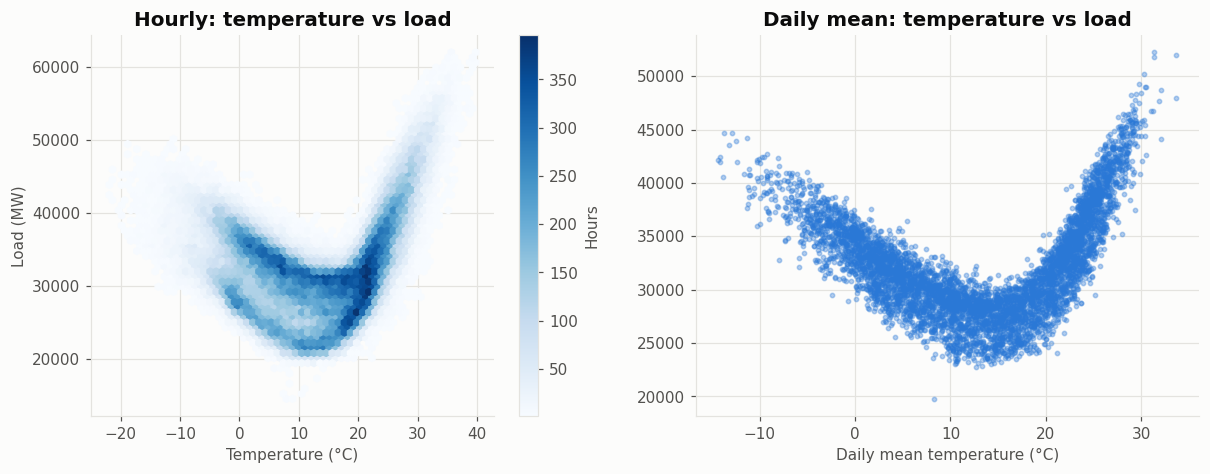

In [8]:
daily_df = df[[TARGET, "temperature_2m"]].resample("D").mean().dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

hb = axes[0].hexbin(df["temperature_2m"], df[TARGET], gridsize=60, cmap="Blues", mincnt=1)
axes[0].set_title("Hourly: temperature vs load")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Load (MW)")
fig.colorbar(hb, ax=axes[0], label="Hours")

axes[1].scatter(daily_df["temperature_2m"], daily_df[TARGET], s=8, alpha=0.35, color=SERIES[0])
axes[1].set_title("Daily mean: temperature vs load")
axes[1].set_xlabel("Daily mean temperature (°C)")
fig.savefig(FIGURES_DIR / "eda_05_temperature_vs_load.png")
plt.show()

In [9]:
# Load is U-shaped in temperature (heating + cooling), so a single Pearson
# correlation understates the relationship. Measure it per regime instead.
# Use 1 °C bins rather than the single lowest day, which is an outlier (Hurricane Sandy).
by_temp = daily_df.groupby(daily_df["temperature_2m"].round())[TARGET].mean()
by_temp = by_temp[daily_df["temperature_2m"].round().value_counts().sort_index() >= 30]
print(f"Mean daily load is lowest at ~{by_temp.idxmin():.0f} °C ({by_temp.min():,.0f} MW)")
for name, mask in {"cold (< 15 °C)": daily_df["temperature_2m"] < 15,
                   "warm (>= 15 °C)": daily_df["temperature_2m"] >= 15}.items():
    r = daily_df.loc[mask, [TARGET, "temperature_2m"]].corr().iloc[0, 1]
    print(f"Pearson r, {name}: {r:+.2f}  (n={mask.sum():,} days)")
print(f"Pearson r, all days: {daily_df.corr().iloc[0, 1]:+.2f}")

Mean daily load is lowest at ~15 °C (26,956 MW)
Pearson r, cold (< 15 °C): -0.85  (n=3,325 days)
Pearson r, warm (>= 15 °C): +0.90  (n=2,734 days)
Pearson r, all days: +0.17


## 7. Findings

**Data quality**
- 145,366 raw rows, 2002-01-01 01:00 to 2018-08-03 00:00, no missing values.
- 4 duplicated timestamps (averaged) and 30 missing hours (all short gaps, interpolated).
  Final grid: 145,392 hourly rows. Temperature joined with zero gaps.
- The 15 lowest hours (below 18,991 MW) all fall on 2012-10-29/30 — Hurricane Sandy.
  This is a real event, not a data error, so it is kept.

**Trend** — no strong long-term trend: yearly mean load ranges only from
30,652 MW (2017) to 33,611 MW (2007). Recent lags will capture the level.

**Daily cycle** — load is lowest around 03:00–05:00 in every season. Summer peaks
at ~17:00 (~43.5k MW); winter has a morning bump and an evening peak at ~19:00 (~38.1k MW);
spring and fall are flatter and lower.

**Weekly cycle** — Tue/Wed average ~33.3k MW versus 30.2k (Sat) and 29.4k (Sun):
weekends are roughly 10% lower. Holidays should behave like weekends.

**Seasonality** — July has the highest median hourly load (37,562 MW) and April the
lowest (28,260 MW); winter is a smaller second peak.

**Temperature** — the relationship is U-shaped: mean daily load is lowest near 15 °C,
rises with heating below it (r = −0.85) and with cooling above it (r = +0.90).
A single linear correlation (r = +0.17) hides this, so a tree model such as LightGBM
(or explicit heating/cooling degree features) is a better fit than a linear one.

**Implications for modelling**
- Strong 24 h and 168 h periodicity makes "same hour yesterday" and "same hour last
  week" sensible baselines, and lag-24 / lag-168 sensible features.
- Hour, weekday, holiday, month and temperature are all clearly informative.